In [5]:
!python -m pip install duckdb


   ---------------------------------------- 0.0/10.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.4/10.3 MB 46.2 MB/s eta 0:00:01
   ----------- ---------------------------- 3.0/10.3 MB 38.5 MB/s eta 0:00:01
   ------------------ --------------------- 4.8/10.3 MB 43.5 MB/s eta 0:00:01
   ------------------------- -------------- 6.7/10.3 MB 42.7 MB/s eta 0:00:01
   -------------------------------- ------- 8.4/10.3 MB 45.0 MB/s eta 0:00:01
   ---------------------------------------  10.1/10.3 MB 46.2 MB/s eta 0:00:01
   ---------------------------------------  10.3/10.3 MB 43.7 MB/s eta 0:00:01
   ---------------------------------------  10.3/10.3 MB 43.7 MB/s eta 0:00:01
   ---------------------------------------  10.3/10.3 MB 43.7 MB/s eta 0:00:01
   ---------------------------------------  10.3/10.3 MB 43.7 MB/s eta 0:00:01
   ---------------------------------------  10.3/10.3 MB 43.7 MB/s eta 0:00:01
   ---------------------------------------  10.3/10.3 MB 43.7 MB/s

In [1]:
import numpy as np
import pandas as pd
import warnings
import json
import psycopg2
import arrow
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb as db
import h2o


In [8]:
engineered_features = db.sql("select sample_number, count(*) as audit_count, max(audit_timestamp) as last_audit_date, min(audit_timestamp) as first_audit_date from read_parquet('C:\MLAR_DATA\T0001\MLAR_RAW_.parquet') group by sample_number").to_df()

In [22]:
engineered_features

,sample_number,audit_count,last_audit_date,first_audit_date
0,6068,6,2020-10-23 11:00:48,2020-10-23 11:00:47
1,6123,5,2020-11-10 05:00:08,2020-11-10 05:00:08
2,6070,5,2020-10-26 04:00:07,2020-10-26 04:00:07
3,6089,4,2020-10-27 14:40:09,2020-10-27 14:31:24
4,6319,5,2021-02-02 05:00:14,2021-02-02 05:00:14
...,...,...,...,...
26653,45918,5,2023-12-04 13:08:32,2023-12-04 12:58:06
26654,45920,5,2023-12-04 13:08:32,2023-12-04 12:58:09
26655,45935,5,2023-12-04 13:08:31,2023-12-04 12:58:45
26656,45931,5,2023-12-04 13:08:31,2023-12-04 12:58:29


In [5]:


# Replace these values with your actual database information
host = "lwanalytics-dev.cwrjruraj02j.us-east-1.rds.amazonaws.com"          # e.g., localhost or your database IP address
database = "locusbio_prod"
user = "locusbio_prod"
password = "4VhBvOJpbb38"
port = "5432"           # e.g., 5432

# Creating the connection string
connection_string = f"host={host} dbname={database} user={user} password={password} port={port}"

# Connecting to the PostgreSQL database
try:
    connection = psycopg2.connect(connection_string)
    print("Connected to the database!")

    # Further actions with the database can be performed here

except psycopg2.Error as e:
    print("Unable to connect to the database.")
    print(e)
finally:
    # Close the connection when done
    if connection:
        connection.close()
        print("Connection closed.")

Connected to the database!
Connection closed.


In [6]:
connection = psycopg2.connect(connection_string)

In [7]:
cursor = connection.cursor()
column_names = ['audit_table_name', 'audit_table_key' ,'audit_counter', 'audit_action' ,'mean_length' , 'audit_type', 'severity']
sql_command = '''

select audit_table_name, audit_table_key ,audit_counter,audit_action, mean_length , audit_type, severity  from t_mlar_log tml 


'''
cursor.execute(sql_command)
queryFetch = cursor.fetchall()
dataFrame = pd.DataFrame.from_records(queryFetch, columns = column_names)

In [8]:
dataFrame

,audit_table_name,audit_table_key,audit_counter,audit_action,mean_length,audit_type,severity
0,TEST,1,2,Insert,7.988080,LogSample,None
1,TEST,2,2,Insert,7.988080,LogSample,None
2,SAMPLE,1,1,Update,7.053319,ModifySample,None
3,SAMPLE,1,1,Update,7.820460,CalculationUpdate,None
4,SAMPLE,618,81,Update,7.666126,Reject,EMPTY
...,...,...,...,...,...,...,...
9548,SAMPLE,983,1,Update,7.472481,Authorize,EMPTY
9549,TEST,2415,80,Delete,7.678406,EditTests,EMPTY
9550,SAMPLE,989,1,Update,7.472481,Authorize,EMPTY
9551,SAMPLE,990,1,Update,7.472481,Authorize,EMPTY


In [9]:
df = db.sql("select * from read_parquet('C:/MLAR_DATA/for_model/T0001/locusbio_model_ready.parquet') ").to_df()

In [10]:
len(df)

657422

In [11]:
df = pd.merge(dataFrame,df,left_on=['audit_table_name','audit_table_key','audit_counter','audit_action','audit_type'],right_on=['table_name','table_key','audit_counter','audit_action','audit_type'],how='right')

In [4]:
df[df['sample_number']==1012]

,sample_number,audit_action,audit_timestamp,audit_type,audit_counter,trans_order,table_name,table_key,record_signed,user_role,...,customer,audit_count,last_audit_date,first_audit_date,distinct_users,distinct_result_names,seconds_to_process,volacity,seconds_since_start,status_no_change
128719,1012,Insert,2023-04-17 13:09:57,LogSample,4,4,TEST,1768,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,0.0,Yes
128725,1012,Insert,2023-04-17 13:09:57,LogSample,5,5,SAMPLE,1012,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,0.0,No
128730,1012,Insert,2023-04-17 13:09:57,LogSample,3,3,RESULT,52286,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,0.0,Yes
128732,1012,Insert,2023-04-17 13:09:57,LogSample,1,1,RESULT,52284,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,0.0,Yes
128733,1012,Insert,2023-04-17 13:09:57,LogSample,2,2,RESULT,52285,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,0.0,Yes
137008,1012,Update,2023-04-19 14:13:09,UpdateBatch,1,1,TEST,1768,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,176592.0,No
137121,1012,Update,2023-04-19 14:13:09,UpdateBatch,2,2,SAMPLE,1012,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,176592.0,No
139730,1012,Update,2023-04-19 18:33:08,EnterResults,5,5,SAMPLE,1012,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,192191.0,No
139731,1012,Update,2023-04-19 18:33:08,EnterResults,4,4,TEST,1768,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,192191.0,No
139732,1012,Update,2023-04-19 18:33:08,EnterResults,3,3,RESULT,52286,F,_ANALYST,...,locusbio,18,2023-06-23 15:45:51,2023-04-17 13:09:57,3,3,5798154.0,0.011176,192191.0,No


In [64]:
len(dataFrame)

6303

In [12]:
df['flagged'] = np.where(df['mean_length'].isna(),'normal','flagged')

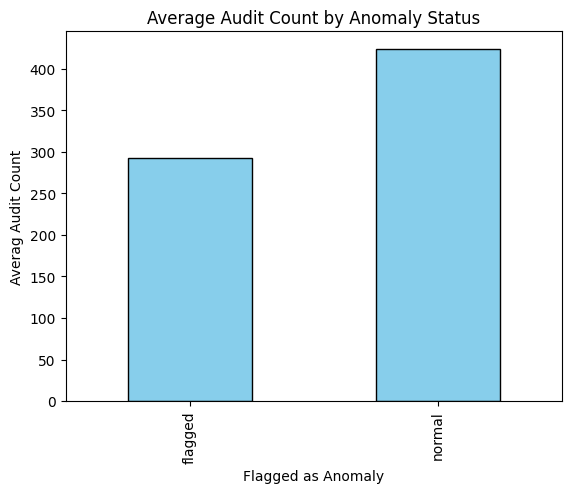

In [13]:
import matplotlib.pyplot as plt
average_values = df.groupby('flagged')['audit_count'].mean()

# Plot the bar chart
average_values.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('Flagged as Anomaly')
plt.ylabel('Averag Audit Count')
plt.title('Average Audit Count by Anomaly Status')

# Show the plot
plt.show()

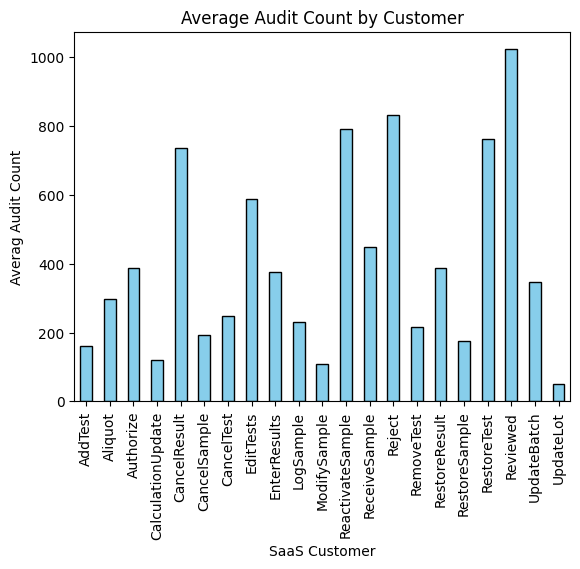

In [14]:
import matplotlib.pyplot as plt
average_values = df[df['flagged']=='flagged'].groupby('audit_type')['audit_count'].mean()

# Plot the bar chart
average_values.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Averag Audit Count')
plt.title('Average Audit Count by Customer')

# Show the plot
plt.show()

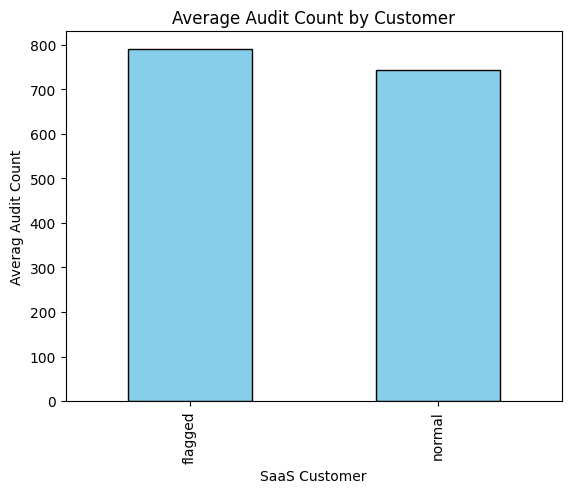

In [15]:
import matplotlib.pyplot as plt
average_values = df[df['audit_type']=='ReactivateSample'].groupby('flagged')['audit_count'].mean()

# Plot the bar chart
average_values.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Averag Audit Count')
plt.title('Average Audit Count by Customer')

# Show the plot
plt.show()

<Axes: xlabel='audit_count', ylabel='Density'>

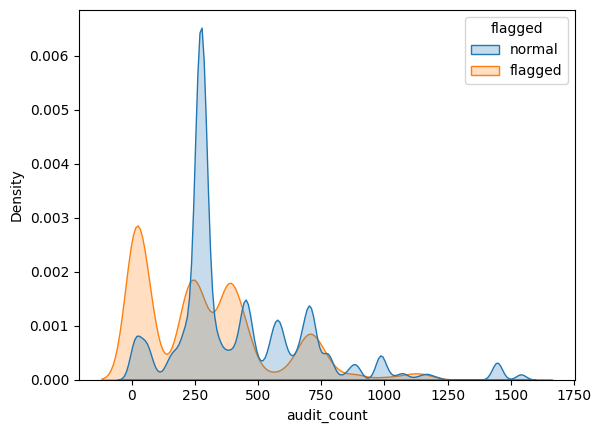

In [16]:
import seaborn as sns
sns.kdeplot(x='audit_count',hue='flagged',data=df,fill=True, common_norm=False)

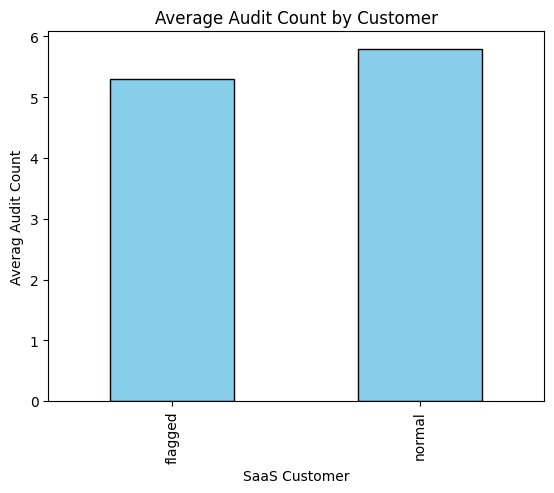

In [17]:
import matplotlib.pyplot as plt
average_values = df[df['audit_type']=='ReactivateSample'].groupby('flagged')['distinct_users'].mean()

# Plot the bar chart
average_values.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Averag Audit Count')
plt.title('Average Audit Count by Customer')

# Show the plot
plt.show()

In [19]:
### When were samples reactivated
df['date'] = df['audit_timestamp'].dt.date
df['hour'] = df['audit_timestamp'].dt.hour


In [20]:
daily_count = df[df['audit_type']=='ReactivateSample'].groupby(['date','flagged']).size().reset_index(name='count')


In [25]:
plt.plot(daily_count['date'], daily_count['count'],color=daily_count['flagged'], marker='o')

# Set labels and title
plt.xlabel('Date')
plt.ylabel('Count')
plt.title('Count of Values by Day')

# Show the plot
plt.show()

NameError: name 'daily_count' is not defined

In [104]:
daily_count

,date,flagged,count
0,2022-01-26,normal,12
1,2022-01-27,normal,6
2,2022-02-08,normal,32
3,2022-02-15,normal,49
4,2022-02-23,normal,108
...,...,...,...
203,2023-10-19,normal,56
204,2023-10-24,normal,11
205,2023-11-02,normal,11
206,2023-11-06,normal,12


In [21]:
sample_reactivated = df[df['audit_type']=='ReactivateSample'].groupby('sample_number')['sample_number'].count()

In [22]:
sample_reactivated = sample_reactivated.reset_index(name='reactivate_count')

(array([95.,  2.,  0., 81., 18.,  1.,  7.,  0.,  6.,  2.]),
 array([  1. ,  26.9,  52.8,  78.7, 104.6, 130.5, 156.4, 182.3, 208.2,
        234.1, 260. ]),
 <BarContainer object of 10 artists>)

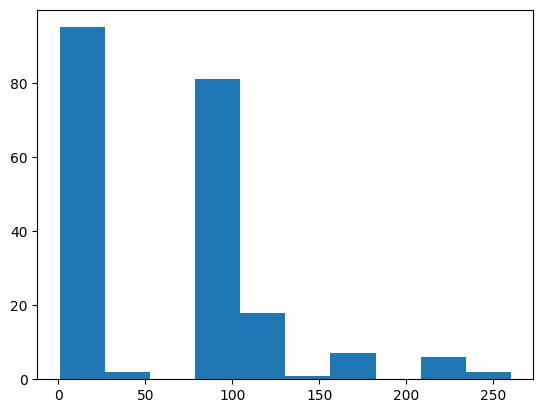

In [23]:
plt.hist(sample_reactivated['reactivate_count'])

In [24]:
sample_reactivated[sample_reactivated['sample_number']== 1432]


,sample_number,reactivate_count


In [29]:
sample_reactivated[sample_reactivated['reactivate_count']>500]

,sample_number,reactivate_count
178,23176,1190
220,23368,1007
629,34380,1015


In [7]:
import h2o
from h2o.estimators import H2OExtendedIsolationForestEstimator, H2ORandomForestEstimator
h2o.init(nthreads=-1,enable_assertions=False)
warnings.filterwarnings('ignore')



Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.391-b13, mixed mode)
  Starting server from C:\Users\dan.larson\AppData\Local\Programs\Python\Python311\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\DAN~1.LAR\AppData\Local\Temp\7\tmpljn5u8q5
  JVM stdout: C:\Users\DAN~1.LAR\AppData\Local\Temp\7\tmpljn5u8q5\h2o_dan_larson_started_from_python.out
  JVM stderr: C:\Users\DAN~1.LAR\AppData\Local\Temp\7\tmpljn5u8q5\h2o_dan_larson_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,06 secs
H2O_cluster_timezone:,America/New_York
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.44.0.2
H2O_cluster_version_age:,3 months and 4 days
H2O_cluster_name:,H2O_from_python_dan_larson_gb53iq
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.476 Gb
H2O_cluster_total_cores:,4
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"


In [30]:
global_surrogate_data = h2o.H2OFrame(df)



Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [31]:
global_surrogate_data

audit_table_name,audit_table_key,audit_counter,audit_action,mean_length,audit_type,severity,sample_number,audit_timestamp,trans_order,table_name,table_key,record_signed,user_role,STATUS_norm,OLD_STATUS_norm,customer,audit_count,last_audit_date,first_audit_date,distinct_users,distinct_result_names,seconds_to_process,volacity,seconds_since_start,status_no_change,flagged
nan,nan,1,Insert,nan,LogSample,nan,6068,2020-10-23 11:00:47,1,RESULT,91757,F,_SCHEDULER,N,N,jaguar,6,2020-10-23 11:00:48,2020-10-23 11:00:47,1,2,1,21600,0,Yes,normal
nan,nan,2,Insert,nan,LogSample,nan,6068,2020-10-23 11:00:47,2,RESULT,91758,F,_SCHEDULER,N,N,jaguar,6,2020-10-23 11:00:48,2020-10-23 11:00:47,1,2,1,21600,0,Yes,normal
nan,nan,3,Insert,nan,LogSample,nan,6068,2020-10-23 11:00:47,3,TEST,15919,F,_SCHEDULER,I,I,jaguar,6,2020-10-23 11:00:48,2020-10-23 11:00:47,1,2,1,21600,0,Yes,normal
nan,nan,4,Insert,nan,LogSample,nan,6068,2020-10-23 11:00:47,4,SAMPLE,6068,F,_SCHEDULER,U,C,jaguar,6,2020-10-23 11:00:48,2020-10-23 11:00:47,1,2,1,21600,0,No,normal
nan,nan,1,Update,nan,ReceiveSample,nan,6068,2020-10-23 11:00:48,1,TEST,15919,F,_SCHEDULER,,,jaguar,6,2020-10-23 11:00:48,2020-10-23 11:00:47,1,2,1,21600,1,No,normal
nan,nan,2,Update,nan,ReceiveSample,nan,6068,2020-10-23 11:00:48,2,SAMPLE,6068,F,_SCHEDULER,I,U,jaguar,6,2020-10-23 11:00:48,2020-10-23 11:00:47,1,2,1,21600,1,No,normal
nan,nan,1,Insert,nan,LogSample,nan,6069,2020-10-26 04:00:06,1,RESULT,91767,F,_SCHEDULER,N,N,jaguar,5,2020-10-26 04:00:06,2020-10-26 04:00:06,1,1,1,18000,0,Yes,normal
nan,nan,2,Update,nan,CancelSample,nan,6080,2020-10-27 14:40:08,2,RESULT,91794,T,_SUPERVISOR,X,,jaguar,8,2020-10-27 14:40:08,2020-10-27 14:31:00,1,2,548,52.5547,548,No,normal
TEST,15942,3,Update,7.74739,CancelSample,,6080,2020-10-27 14:40:08,3,TEST,15942,T,_SUPERVISOR,X,,jaguar,8,2020-10-27 14:40:08,2020-10-27 14:31:00,1,2,548,52.5547,548,No,flagged
nan,nan,4,Update,nan,CancelSample,nan,6080,2020-10-27 14:40:08,4,SAMPLE,6080,T,_SUPERVISOR,X,U,jaguar,8,2020-10-27 14:40:08,2020-10-27 14:31:00,1,2,548,52.5547,548,No,normal


In [34]:
fieldDictUnsupervised = ['audit_action','audit_timestamp','audit_type','audit_counter','trans_order','table_name','record_signed','user_role','audit_count','seconds_to_process','volacity','seconds_since_start', 'seconds_since_start','distinct_users','distinct_result_names','status_no_change']


In [35]:
from h2o.estimators import H2ORandomForestEstimator

global_surrogate_dt = H2ORandomForestEstimator(model_id = "global_surrogate_decision_tree.hex", 
                                               ntrees = 1, max_depth = 3,
                                               sample_rate = 1, mtries = -1)
global_surrogate_dt.train(training_frame = global_surrogate_data, x = fieldDictUnsupervised, y = "flagged")

drf Model Build progress: |██████████████████████████████████████████████████████| (done) 100%


Model Details
=============
H2ORandomForestEstimator : Distributed Random Forest
Model Key: global_surrogate_decision_tree.hex


Model Summary: 
    number_of_trees    number_of_internal_trees    model_size_in_bytes    min_depth    max_depth    mean_depth    min_leaves    max_leaves    mean_leaves
--  -----------------  --------------------------  ---------------------  -----------  -----------  ------------  ------------  ------------  -------------
    1                  1                           158                    3            3            3             8             8             8

ModelMetricsBinomial: drf
** Reported on train data. **

MSE: NaN
RMSE: NaN
LogLoss: NaN
Mean Per-Class Error: NaN
AUC: NaN
AUCPR: NaN
Gini: NaN

Scoring History: 
    timestamp            duration    number_of_trees    training_rmse    training_logloss    training_auc    training_pr_auc    training_lift    training_classification_error
--  -------------------  ----------  -----------------  ---------------  ------------------  --------------  -----------------  ---------------  -------------------------------
    2024-02-12 15:38:55  0.292 sec   0                  nan              nan                 nan             nan                nan              nan

Variable Importances: 
variable               relative_importance    scaled_importance    percentage
---------------------  ---------------------  -------------------  ------------
audit_counter          4131.33                1                    0.975916
audit_timestamp        67.7102                0.0163894            0.0159947
audit_type             23.4849                0.00568459           0.00554768
distinct_users         8.11804                0.00196499           0.00191767
audit_action           2.64107                0.000639278          0.000623882
trans_order            0                      0                    0
table_name             0                      0                    0
record_signed          0                      0                    0
user_role              0                      0                    0
audit_count            0                      0                    0
distinct_result_names  0                      0                    0
seconds_to_process     0                      0                    0
volacity               0                      0                    0
seconds_since_start    0                      0                    0
status_no_change       0                      0                    0

[tips]
Use `model.explain()` to inspect the model.
--
Use `h2o.display.toggle_user_tips()` to switch on/off this section.

# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## global_surrogate_decision_tree.hex

,flagged,normal,Error,Rate
flagged,4593.0,1967.0,0.2998,(1967.0/6560.0)
normal,403.0,564590.0,0.0007,(403.0/564993.0)
Total,4996.0,566557.0,0.0041,(2370.0/571553.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

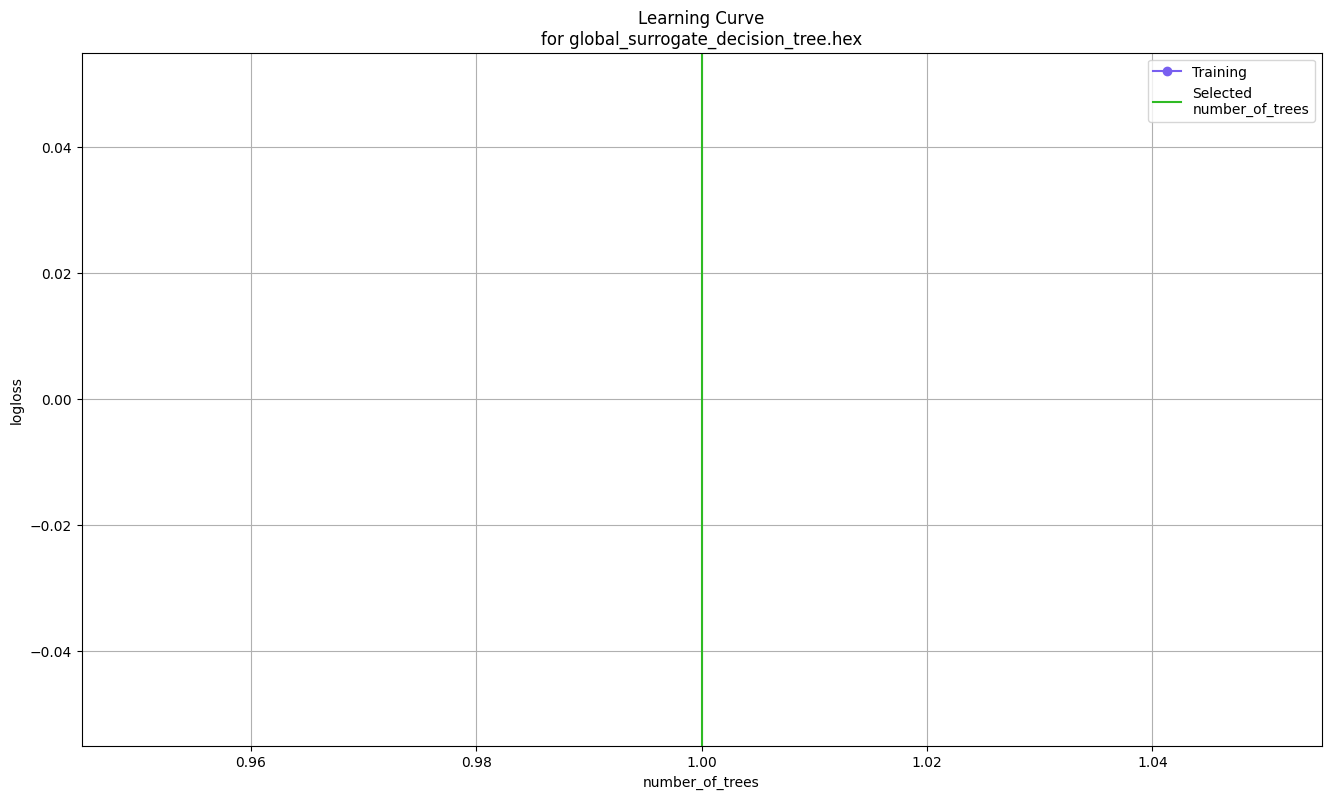

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

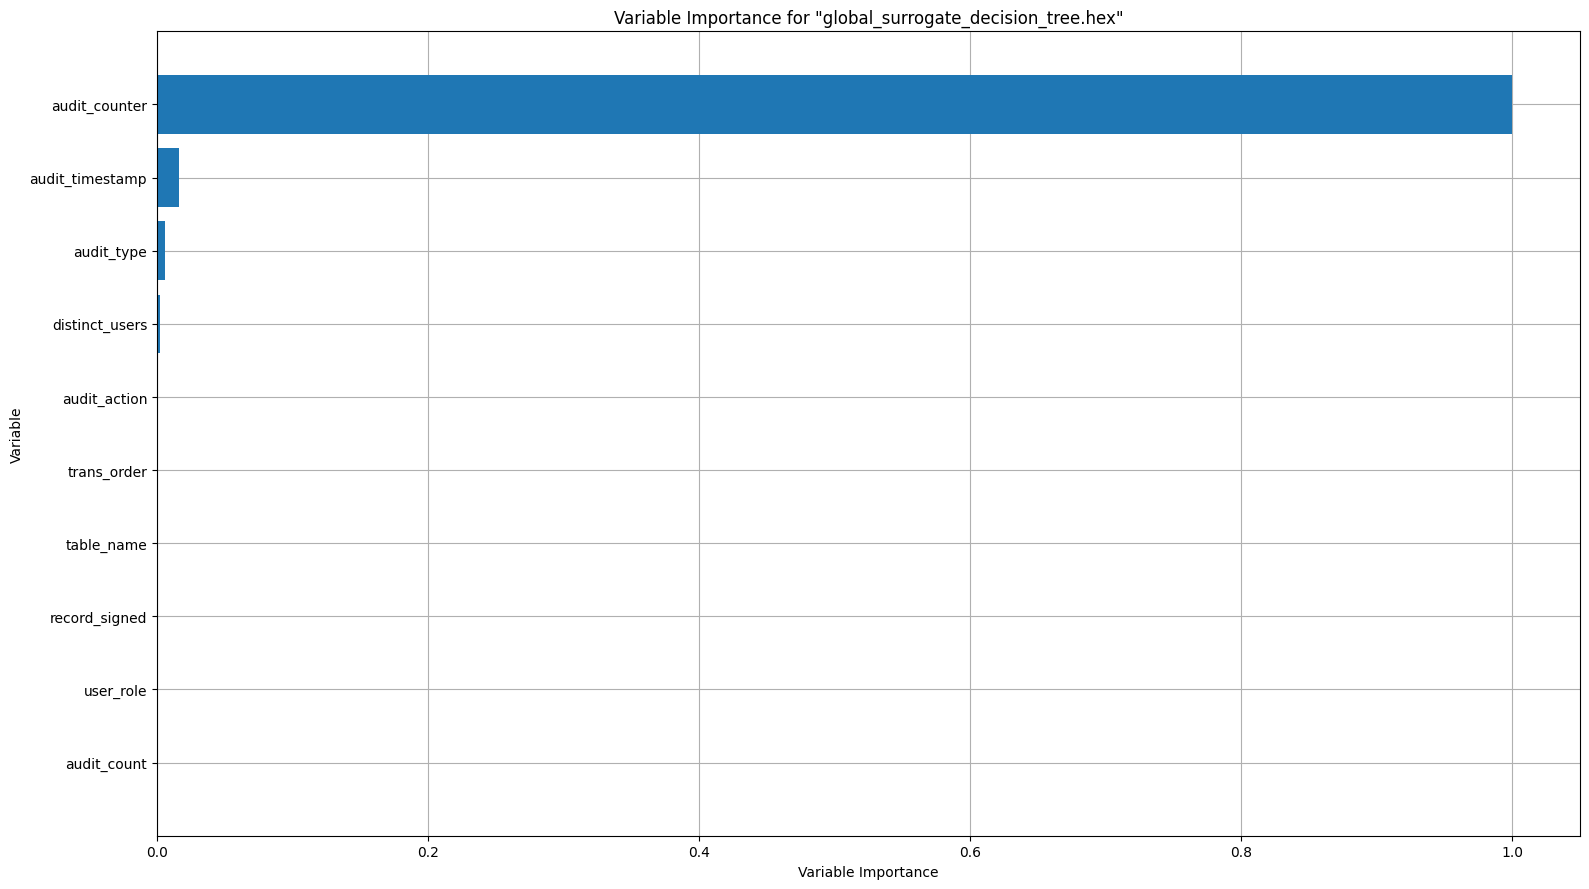

# SHAP Summary

> SHAP summary plot shows the contribution of the features for each instance (row of data). The sum of the feature contributions and the bias term is equal to the raw prediction of the model, i.e., prediction before applying inverse link function.

In [36]:
global_surrogate_dt.explain(global_surrogate_data)